# EDA — USB e USA: a frota do SAMU não é homogênea

Este caderno é o passo que faltava antes do MCLP do `prototipo_samu.ipynb`.
Lá, cada ambulância vale uma ambulância. Aqui a pergunta é outra:

> **A frota é feita de dois equipamentos clinicamente diferentes — Unidade de
> Suporte Básico (USB) e Unidade de Suporte Avançado (USA). Eles estão
> distribuídos do mesmo jeito?**

A resposta é não, e a diferença é grande o bastante para mudar a formulação do
modelo de localização.

**Escopo:** Brasil inteiro, 5.570 municípios, competência dez/2024 do CNES mais o
Censo 2022 do IBGE.

## 1. De onde vêm os dados

| o quê | fonte | por quê essa e não outra |
|---|---|---|
| unidades móveis | API de Dados Abertos do MS, `cnes/estabelecimentos`, `codigo_tipo_unidade=42` | traz `nome_fantasia` e **coordenada** de cada base — o arquivo ST do DATASUS não traz nenhum dos dois |
| modalidade (USB/USA/…) | CNES grupo **SR** via `pysus`, serviço `103` + `CLASS_SR` | único campo *estruturado* que separa básico de avançado |
| população, área | IBGE, agregado 4714 do Censo 2022, nível N6 | mesma base do protótipo |
| geometria municipal | malha do IBGE (`qualidade=minima`) | centroide do polígono |
| sede municipal | CSV de terceiros (`kelvins/municipios-brasileiros`), que republica coordenadas de sede de origem IBGE | onde a população de fato está — ver §8. A API de localidades do IBGE não devolve coordenada de sede; a alternativa oficial é o BCIM, só por download manual |

Os scripts de coleta estão ao lado deste caderno (`pull_*.py`). Rodam uma vez e
gravam em `dados/`. Daqui para frente o caderno só lê o que já está em disco.

> **Armadilha que custou tempo:** a API de dados abertos ignora o parâmetro
> `limit` e devolve no máximo 20 registros por página. Paginar com
> `offset += limit` *pula* registros silenciosamente — o primeiro puxão de SP
> devolveu 280 unidades em vez de 1.358. O certo é `offset += len(lote)`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DADOS = Path("dados")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False})
C_USB, C_USA, C_OUT = "#2E7D9A", "#C1442E", "#B9BDC1"

frota = pd.read_parquet(DADOS / "frota.parquet")      # 1 linha por unidade
mun   = pd.read_parquet(DADOS / "municipal.parquet")  # 1 linha por município

POP = mun.populacao.sum()
print(f"{len(frota)} unidades tipo 42 | {len(mun)} municipios | "
      f"{POP/1e6:.1f} mi hab")

7123 unidades tipo 42 | 5570 municipios | 203.1 mi hab


## 2. Como USB e USA foram separadas

Não existe campo `tipo_de_ambulancia` no CNES. Há dois caminhos, e os dois são
imperfeitos:

1. **`nome_fantasia`** — texto livre. `"SAMU USB 03"` é fácil; `"SAMU 192 BASE
   DESCENTRALIZADA"` não diz nada.
2. **Serviço especializado (grupo SR)** — o serviço `103` tem uma classificação
   (`CLASS_SR`) por unidade. Estruturado, mas só existe para quem declarou
   serviço.

A tabela oficial de classificações do CNES não estava acessível pelo FTP do
DATASUS a partir desta rede, então o mapa `CLASS_SR → modalidade` foi **inferido
cruzando com os nomes** e depois usado como classificador primário.

In [2]:
ct = pd.crosstab(frota.CLASS_SR, frota.cls_nome)
cols = [c for c in ["USB", "USA", "MOTOLANCIA", "AEREA", "AQUATICA",
                    "INDETERMINADO"] if c in ct.columns]
display(ct[cols])

cls_nome,USB,USA,MOTOLANCIA,AEREA,AQUATICA,INDETERMINADO
CLASS_SR,,,,,,
001,44,21,0,0,0,254
002,1810,10,0,1,0,1768
003,7,648,0,0,0,232
005,0,0,0,0,15,2
006,0,1,0,0,0,12
007,0,0,0,0,0,17
008,7,0,0,0,0,104
010,0,0,293,0,0,48
011,0,0,0,0,1,0


Leitura da tabela: em `CLASS_SR = 002` há 1.810 nomes de USB contra 10 de USA; em
`003`, 648 USA contra 7 USB. **Concordância acima de 98% nos dois casos.** Os
demais códigos saem limpos: `010` é motolância, `012` aéreo, `005`/`011`
aquático, `006` VIR.

Daí o mapa usado em `base_frota.py`:

| `CLASS_SR` | modalidade |
|---|---|
| 002 | USB |
| 003 | USA |
| 010 | MOTOLÂNCIA |
| 012 | AÉREA |
| 005, 011 | AQUÁTICA |
| 006 | VIR |
| 001, 007, 008 | RESGATE/OUTROS |

A regra final: **código de serviço quando existe, nome quando não existe,
`INDETERMINADO` quando nenhum dos dois resolve.**

In [3]:
ativas = frota[frota.ativo]
print(ativas.fonte_class.value_counts().to_string())
print()
print("nomes que nao classificam nada: "
      f"{(ativas.cls_nome == 'INDETERMINADO').mean()*100:.1f}% das unidades ativas")

fonte_class
servico_cnes        5257
nome_fantasia        396
nao_classificada     338

nomes que nao classificam nada: 45.6% das unidades ativas


**Registre isso no trabalho:** classificar unidade móvel por nome fantasia falha
em quase metade dos casos. Quem fizer esta análise só com o texto do CNES vai
descartar ~46% da frota ou, pior, classificá-la errado.

## 3. O universo: nem tudo que é tipo 42 é SAMU

`TP_UNID = 42` é "unidade móvel de nível pré-hospitalar na área de urgência".
Isso inclui empresas privadas de remoção, Corpo de Bombeiros e unidades já
desabilitadas. Antes de contar qualquer coisa, é preciso limpar.

In [4]:
print(f"cadastradas ............ {len(frota):5d}")
print(f"  desabilitadas ........ {(~frota.ativo).sum():5d}")
print(f"  ativas ............... {frota.ativo.sum():5d}")
print(f"    privadas ........... {(ativas.setor == 'privado').sum():5d}")
print(f"    publicas/filantrop.. "
      f"{ativas.setor.isin(['publico','sem_fins_lucrativos']).sum():5d}")
print(f"sem coordenada ......... {frota.lat.isna().sum():5d}  "
      "(quase todas entre as desabilitadas)")

publicas = ativas[ativas.setor.isin(["publico", "sem_fins_lucrativos"])]

cadastradas ............  7123
  desabilitadas ........  1132
  ativas ...............  5991
    privadas ...........   468
    publicas/filantrop..  5522
sem coordenada .........   642  (quase todas entre as desabilitadas)


Do cadastro bruto (7.123) sobram **5.522 unidades públicas ativas**. Usar o
número cheio infla a frota em 29% e mistura ambulância de convênio com SAMU.

## 4. Composição da frota

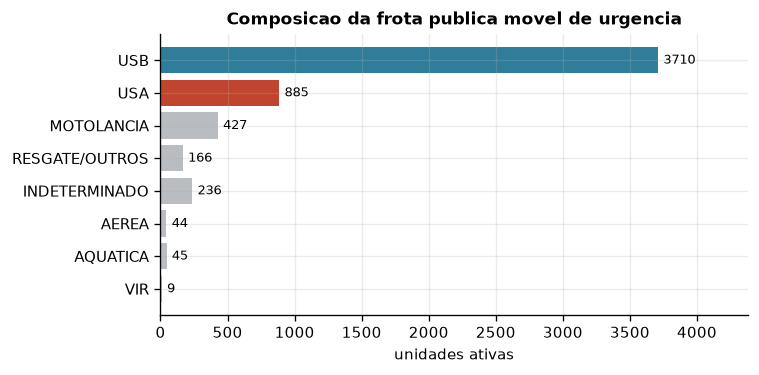

USB 3710 | USA 885 | razao 4.19 USB por USA
54,739 hab por USB | 229,470 hab por USA


In [5]:
ordem = ["USB", "USA", "MOTOLANCIA", "RESGATE/OUTROS", "INDETERMINADO",
         "AEREA", "AQUATICA", "VIR"]
comp = publicas.modalidade.value_counts().reindex(ordem).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.barh(range(len(comp))[::-1], comp.values, color=[C_USB, C_USA] + [C_OUT] * 6)
ax.set_yticks(range(len(comp))[::-1]); ax.set_yticklabels(comp.index)
for i, v in enumerate(comp.values):
    ax.text(v + 40, len(comp) - 1 - i, str(v), va="center", fontsize=8)
ax.set_xlim(0, comp.max() * 1.18); ax.set_xlabel("unidades ativas")
ax.set_title("Composicao da frota publica movel de urgencia",
             fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

usb, usa = comp["USB"], comp["USA"]
print(f"USB {usb} | USA {usa} | razao {usb/usa:.2f} USB por USA")
print(f"{POP/usb:,.0f} hab por USB | {POP/usa:,.0f} hab por USA")

Uma USA para cada 4,2 USB. Em habitantes: **1 USB a cada 55 mil**, **1 USA a cada
229 mil**. Os dois números batem com a ordem de grandeza das portarias do
Ministério (1 USB por 100–150 mil, 1 USA por 400–450 mil) — a rede *no agregado*
está dimensionada. O problema não é quantidade. É onde estão.

## 5. Quem tem ambulância na própria cidade

,municipios,pop_mi,% com USB,% com USA,hab/USB,hab/USA
faixa,,,,,,
<5k,1324.0,4.4,8.5,0.2,38632.7,2221378.0
5-10k,1170.0,8.3,25.6,0.4,27418.2,1667027.4
10-20k,1366.0,19.2,50.4,2.6,27072.8,519505.6
20-50k,1053.0,32.0,71.7,14.7,39214.7,202278.3
50-100k,338.0,23.5,80.5,47.0,63624.0,137293.8
100-200k,167.0,22.5,89.8,72.5,75107.4,159270.3
200-500k,111.0,34.3,94.6,91.0,79449.2,213180.4
>=500k,41.0,58.9,100.0,100.0,88385.5,280308.4


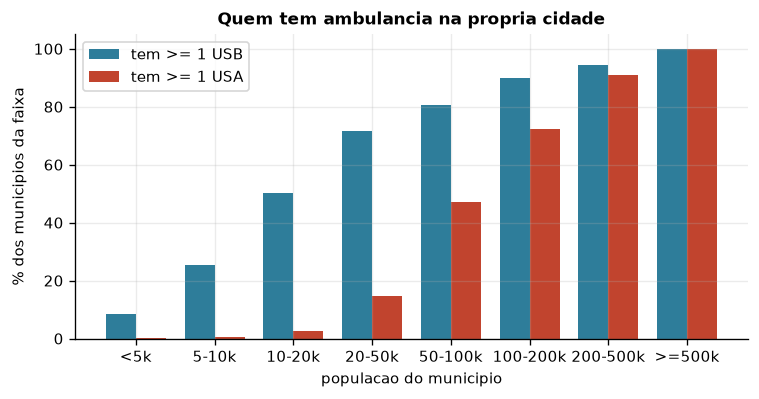

In [6]:
faixas = [0, 5e3, 1e4, 2e4, 5e4, 1e5, 2e5, 5e5, 1e10]
rot = ["<5k", "5-10k", "10-20k", "20-50k", "50-100k", "100-200k",
       "200-500k", ">=500k"]
mun["faixa"] = pd.cut(mun.populacao, faixas, labels=rot, right=False)

g = mun.groupby("faixa", observed=True).apply(lambda d: pd.Series({
    "municipios": len(d),
    "pop_mi": d.populacao.sum() / 1e6,
    "% com USB": d.tem_usb.mean() * 100,
    "% com USA": d.tem_usa.mean() * 100,
    "hab/USB": d.populacao.sum() / max(d.USB.sum(), 1),
    "hab/USA": d.populacao.sum() / max(d.USA.sum(), 1),
}), include_groups=False)
display(g.round(1))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
x = np.arange(len(g)); w = .38
ax.bar(x - w/2, g["% com USB"], w, color=C_USB, label="tem >= 1 USB")
ax.bar(x + w/2, g["% com USA"], w, color=C_USA, label="tem >= 1 USA")
ax.set_xticks(x); ax.set_xticklabels(g.index); ax.set_ylim(0, 105)
ax.set_ylabel("% dos municipios da faixa")
ax.set_xlabel("populacao do municipio")
ax.set_title("Quem tem ambulancia na propria cidade",
             fontsize=10, fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()

O degrau é brutal. Entre os 1.324 municípios com menos de 5 mil habitantes,
**0,2% têm uma USA** — dois municípios no país inteiro. Acima de 200 mil, é
praticamente universal.

E repare na coluna `hab/USB`: ela **sobe** com o tamanho do município (27 mil nos
pequenos, 88 mil nos grandes). Municípios pequenos que *têm* USB têm frota
per capita folgada; o problema deles não é densidade de frota, é ausência
completa dela.

## 6. Concentração

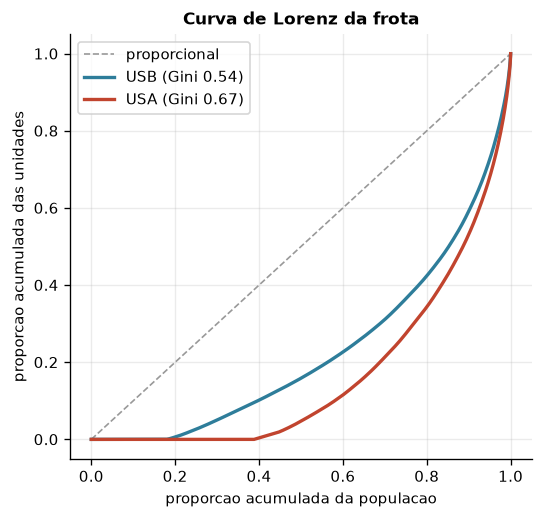

In [7]:
def lorenz(x, w):
    o = np.argsort(x / np.where(w == 0, np.nan, w))
    x, w = np.asarray(x)[o], np.asarray(w)[o]
    return np.r_[0, np.cumsum(w) / w.sum()], np.r_[0, np.cumsum(x) / x.sum()]


def gini(x, w):
    cw, cx = lorenz(x, w)
    return float(1 - np.sum((cw[1:] - cw[:-1]) * (cx[1:] + cx[:-1])))


fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="proporcional")
for mod, cor in [("USB", C_USB), ("USA", C_USA)]:
    cw, cx = lorenz(mun[mod].values, mun.populacao.values)
    gi = gini(mun[mod].values, mun.populacao.values)
    ax.plot(cw, cx, color=cor, lw=2, label=f"{mod} (Gini {gi:.2f})")
ax.set_xlabel("proporcao acumulada da populacao")
ax.set_ylabel("proporcao acumulada das unidades")
ax.set_title("Curva de Lorenz da frota", fontsize=10, fontweight="bold")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

Gini de 0,54 para USB e **0,67 para USA**, tomando população como referência de
"justo". Não é desigualdade de renda — é desigualdade de acesso a um recurso que
decide sobrevivência em parada cardíaca e trauma grave.

## 7. A regra populacional funciona?

Se a frota fosse alocada proporcionalmente à população, a elasticidade de
`log(unidades)` contra `log(população)` seria 1. Não é.

log(total) ~ log(pop):  elasticidade 0.42   R2 0.57   n=2649
log(USB  ) ~ log(pop):  elasticidade 0.29   R2 0.47   n=2423
log(USA  ) ~ log(pop):  elasticidade 0.26   R2 0.41   n=619


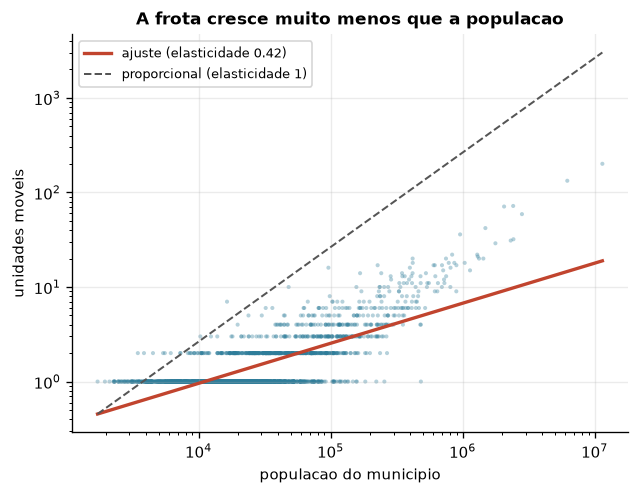

In [8]:
def elasticidade(sub, col):
    x, y = np.log(sub.populacao.values), np.log(sub[col].values)
    b, a = np.polyfit(x, y, 1)
    r2 = 1 - ((y - (a + b * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return b, r2, len(sub), a


for col, sub in [("total", mun[mun.total > 0]),
                 ("USB", mun[mun.USB > 0]),
                 ("USA", mun[mun.USA > 0])]:
    b, r2, n, _ = elasticidade(sub, col)
    print(f"log({col:5s}) ~ log(pop):  elasticidade {b:.2f}   R2 {r2:.2f}   n={n}")

c = mun[mun.total > 0]
b, r2, n, a0 = elasticidade(c, "total")
fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.scatter(c.populacao, c.total, s=6, color=C_USB, alpha=.35, edgecolor="none")
xs = np.logspace(np.log10(c.populacao.min()), np.log10(c.populacao.max()), 50)
ax.plot(xs, np.exp(a0) * xs ** b, color=C_USA, lw=2,
        label=f"ajuste (elasticidade {b:.2f})")
ax.plot(xs, np.exp(a0) * xs.min() ** b * (xs / xs.min()), color="#555",
        ls="--", lw=1.2, label="proporcional (elasticidade 1)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("populacao do municipio"); ax.set_ylabel("unidades moveis")
ax.set_title("A frota cresce muito menos que a populacao",
             fontsize=10, fontweight="bold")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Elasticidade de **0,42** no total e **0,29** só para USB. Dobrar a população de um
município multiplica sua frota por 1,3, não por 2.

Cuidado com a interpretação: isso **não** prova que a alocação é irracional.
Ambulância não é bem privado — ela cobre um raio, e num município denso o mesmo
veículo alcança mais gente. Sublinearidade é esperada. O que o número mostra é
que **população sozinha explica pouco** (R² de 0,57), o que é exatamente o
argumento para trocar a regra populacional por um modelo de cobertura.

## 8. Tempo até a unidade mais próxima

Aqui o caderno encosta no protótipo. Para cada município, a distância haversine
até a base mais próxima de cada modalidade, com o mesmo fator de sinuosidade
1,35 e 55 km/h do `prototipo_samu.ipynb`.

**O ponto de referência importa muito.** O protótipo usa o centroide do polígono
municipal. Em Altamira (159 mil km²) ou Jutaí, o centroide fica a centenas de
quilômetros da sede — onde a população e a ambulância de fato estão. As duas
versões estão em `municipal.parquet`: `t_USB`/`t_USA` a partir da **sede**,
`t_USB_cent`/`t_USA_cent` a partir do **centroide**.

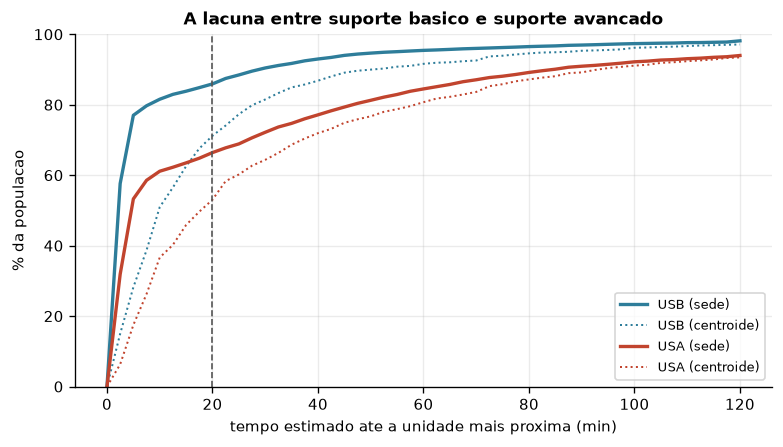

USB (sede     ): mediana  15.3 min | <=20 min cobre  85.9% da populacao
USB (centroide): mediana  21.9 min | <=20 min cobre  71.2% da populacao
USA (sede     ): mediana  44.8 min | <=20 min cobre  66.4% da populacao
USA (centroide): mediana  47.2 min | <=20 min cobre  53.1% da populacao


In [9]:
lims = np.arange(0, 121, 2.5)
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for mod, cor in [("USB", C_USB), ("USA", C_USA)]:
    y = [mun.loc[mun[f"t_{mod}"] <= L, "populacao"].sum() / POP * 100 for L in lims]
    yc = [mun.loc[mun[f"t_{mod}_cent"] <= L, "populacao"].sum() / POP * 100
          for L in lims]
    ax.plot(lims, y, color=cor, lw=2, label=f"{mod} (sede)")
    ax.plot(lims, yc, color=cor, lw=1.2, ls=":", label=f"{mod} (centroide)")
ax.axvline(20, color="#555", ls="--", lw=1)
ax.set_xlabel("tempo estimado ate a unidade mais proxima (min)")
ax.set_ylabel("% da populacao"); ax.set_ylim(0, 100)
ax.set_title("A lacuna entre suporte basico e suporte avancado",
             fontsize=10, fontweight="bold")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

for mod in ["USB", "USA"]:
    for suf, nome in [("", "sede     "), ("_cent", "centroide")]:
        t = mun[f"t_{mod}{suf}"]
        cob = mun.loc[t <= 20, "populacao"].sum() / POP * 100
        print(f"{mod} ({nome}): mediana {t.median():5.1f} min | "
              f"<=20 min cobre {cob:5.1f}% da populacao")

Duas conclusões, e a segunda é a que interessa ao projeto.

**(a) O ponto de referência move o resultado em ~15 p.p.** Cobertura de USB em 20
minutos: 85,9% pela sede, 71,2% pelo centroide. O protótipo usa centroide e
portanto **subestima** a cobertura atual. Isso precisa estar declarado — ou
trocado por setor censitário, como já está previsto nos próximos passos.

**(b) USB e USA não cobrem o mesmo país.**

In [10]:
L = 20.0
tem_usb, tem_usa = mun.t_USB <= L, mun.t_USA <= L
quadro = {
    "USB e USA em ate 20 min": (tem_usb & tem_usa),
    "so USB (USA distante)":   (tem_usb & ~tem_usa),
    "nenhuma das duas":        (~tem_usb & ~tem_usa),
}
for k, v in quadro.items():
    p = mun.loc[v, "populacao"].sum()
    print(f"{k:26s} {p/1e6:6.1f} mi ({p/POP*100:4.1f}%) | {v.sum():5d} municipios")

USB e USA em ate 20 min     133.9 mi (66.0%) |  1003 municipios
so USB (USA distante)        40.6 mi (20.0%) |  2196 municipios
nenhuma das duas             27.5 mi (13.6%) |  2340 municipios


**40,6 milhões de brasileiros têm uma ambulância básica a 20 minutos e nenhuma
unidade avançada.** Para infarto com supradesnivelamento, AVC ou trauma grave,
essa população está descoberta — mesmo aparecendo como "coberta" em qualquer
modelo que trate a frota como homogênea.

Outros 27,5 milhões não têm nem uma nem outra.

## 9. Onde estão as bases

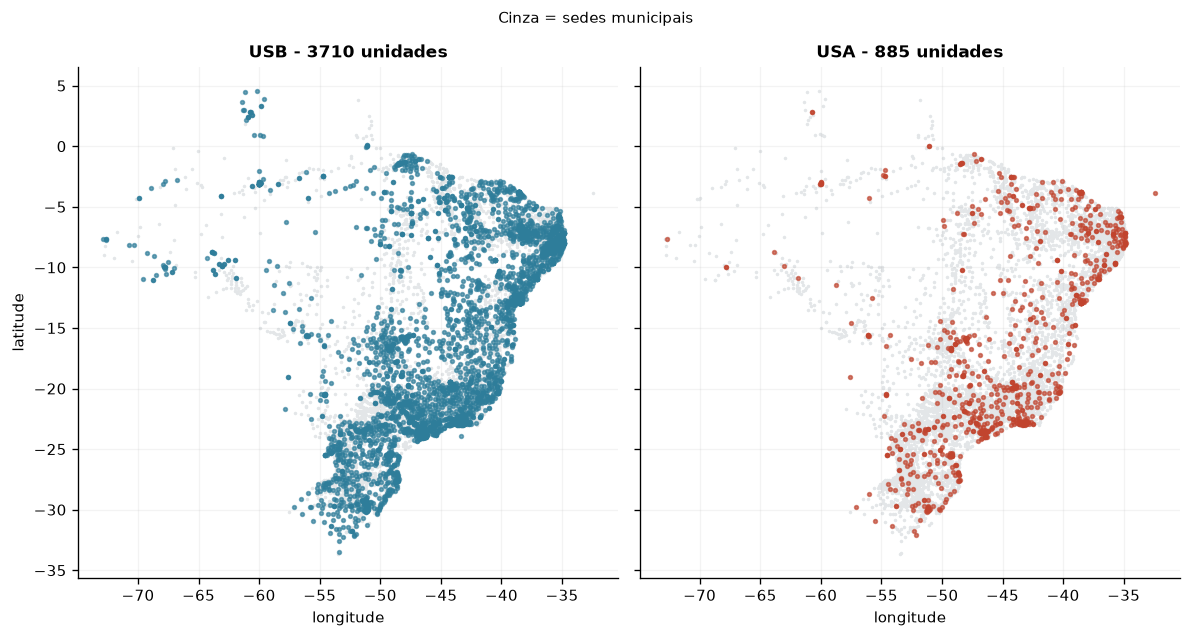

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), sharex=True, sharey=True)
for ax, (mod, cor) in zip(axes, [("USB", C_USB), ("USA", C_USA)]):
    ax.scatter(mun.lon_sede, mun.lat_sede, s=1.2, color="#E3E6E8", zorder=1)
    s = publicas[publicas.modalidade == mod]
    ax.scatter(s.lon, s.lat, s=5, color=cor, alpha=.65, zorder=2)
    ax.set_title(f"{mod} - {len(s)} unidades", fontsize=10, fontweight="bold")
    ax.set_aspect(1.0); ax.grid(alpha=.15); ax.set_xlabel("longitude")
axes[0].set_ylabel("latitude")
fig.suptitle("Cinza = sedes municipais", fontsize=9)
plt.tight_layout(); plt.show()

## 10. Por UF

,pop_mi,USB,USA,USB/100k,USA/100k,cob_USB_20,cob_USA_20,lacuna_pp
uf_sigla,,,,,,,,
PA,8.12,120.0,18.0,1.48,0.22,80.89,38.01,42.88
TO,1.51,16.0,5.0,1.06,0.33,52.14,39.36,12.78
MT,3.66,34.0,10.0,0.93,0.27,56.16,42.20,13.96
RO,1.58,25.0,3.0,1.58,0.19,50.98,43.11,7.87
PI,3.27,128.0,19.0,3.91,0.58,82.57,48.70,33.87
MA,6.78,118.0,35.0,1.74,0.52,66.03,49.97,16.06
MS,2.76,28.0,7.0,1.02,0.25,66.62,50.47,16.15
AL,3.13,49.0,14.0,1.57,0.45,84.48,50.96,33.52
AM,3.94,60.0,8.0,1.52,0.20,68.64,52.36,16.28


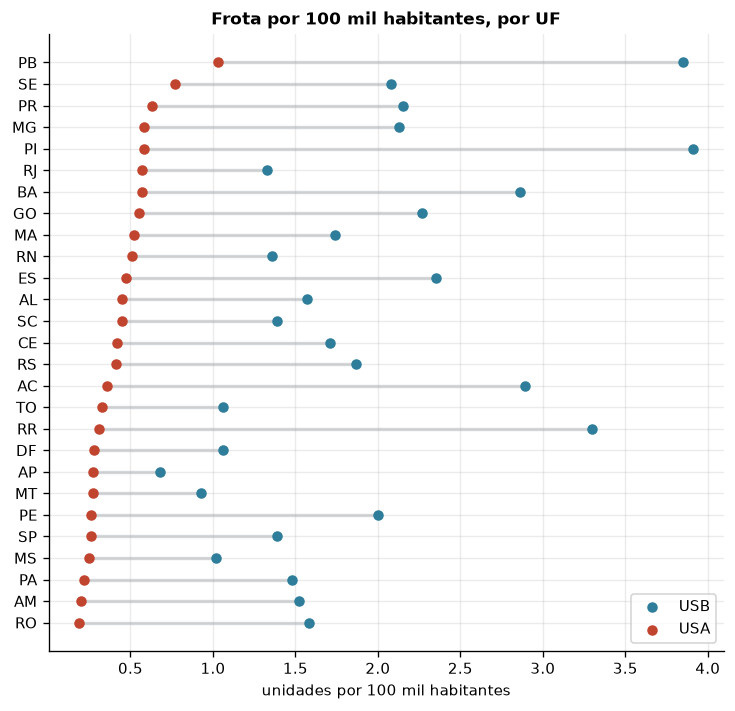

In [12]:
pop_uf = mun.groupby("uf_sigla").populacao.sum()
u = publicas.pivot_table(index="uf_sigla", columns="modalidade",
                         values="codigo_cnes", aggfunc="count").fillna(0)
tab = pd.DataFrame({
    "pop_mi": pop_uf / 1e6,
    "USB": u.USB, "USA": u.USA,
    "USB/100k": u.USB / pop_uf * 1e5, "USA/100k": u.USA / pop_uf * 1e5,
    "cob_USB_20": mun.groupby("uf_sigla").apply(
        lambda d: d.loc[d.t_USB <= 20, "populacao"].sum() / d.populacao.sum() * 100,
        include_groups=False),
    "cob_USA_20": mun.groupby("uf_sigla").apply(
        lambda d: d.loc[d.t_USA <= 20, "populacao"].sum() / d.populacao.sum() * 100,
        include_groups=False),
}).round(2)
tab["lacuna_pp"] = (tab.cob_USB_20 - tab.cob_USA_20).round(2)
display(tab.sort_values("cob_USA_20"))

t = tab.sort_values("USA/100k")
fig, ax = plt.subplots(figsize=(6.2, 6))
y = np.arange(len(t))
ax.hlines(y, t["USA/100k"], t["USB/100k"], color="#D6D9DC", lw=2, zorder=1)
ax.scatter(t["USB/100k"], y, color=C_USB, s=28, zorder=2, label="USB")
ax.scatter(t["USA/100k"], y, color=C_USA, s=28, zorder=2, label="USA")
ax.set_yticks(y); ax.set_yticklabels(t.index)
ax.set_xlabel("unidades por 100 mil habitantes")
ax.set_title("Frota por 100 mil habitantes, por UF",
             fontsize=10, fontweight="bold")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

A taxa de USA varia **cinco vezes** entre estados: 0,19 por 100 mil em Rondônia
contra 1,03 na Paraíba. A de USB varia quatro vezes. Nenhuma das duas acompanha
população, densidade ou região de forma limpa.

A coluna `lacuna_pp` é a diferença entre cobertura básica e avançada em 20
minutos. O Pará lidera com 42,9 p.p. — quase metade da população paraense tem
socorro básico perto e avançado longe.

## 11. O que isso muda no protótipo

O `prototipo_samu.ipynb` resolve um MCLP com `p` bases idênticas. Os dados dizem
que essa é a hipótese errada. Três consequências concretas:

**1. O modelo tem que ser de dois níveis.** Duas frotas, dois limiares, uma
função objetivo que pondera as duas:

$$\max \sum_i w_i \big(\alpha\, y_i^{B} + (1-\alpha)\, y_i^{A}\big)
\quad\text{s.a.}\quad
y_i^{B} \le \sum_{j:\,a_{ij}=1} x_j^{B},\quad
y_i^{A} \le \sum_{j:\,a_{ij}=1} x_j^{A},\quad
\sum_j x_j^{B} = p_B,\quad \sum_j x_j^{A} = p_A$$

com $p_B$ e $p_A$ fixados nos totais observados. O ganho a reportar deixa de ser
um número e passa a ser dois — e o de USA é onde há espaço real.

**2. O contrafactual muda.** Realocar 3.710 USB rende pouco: a cobertura básica
já é 85,9% e é cara de melhorar. Realocar 885 USA parte de 66,4% — é ali que uma
otimização tem de onde tirar ganho.

**3. Cobertura hierárquica.** Uma USA atende chamado de baixa complexidade; uma
USB não atende chamado de alta. Se o modelo levar isso a sério, USA cobre demanda
básica e avançada, USB só cobre básica. Isso é *backup coverage* — e reforça a
conclusão de que o gargalo é o suporte avançado.

**Próximo passo recomendado:** rodar o protótipo com `MODO = "real"`, mas
substituindo `n_ambulancias` por duas colunas (`USB`, `USA`), e comparar o ganho
da realocação em cada camada. `dados/municipal.parquet` já sai pronto para isso.

## 12. Limitações — o que declarar no trabalho

1. **Classificação inferida.** O mapa `CLASS_SR → USB/USA` foi validado contra
   nomes (>98% de concordância), não contra a tabela oficial do CNES, que não
   estava acessível. 4,3% das unidades ativas ficaram sem modalidade.
2. **Tempo é haversine, não rota.** Fator 1,35 sobre a linha reta a 55 km/h.
   Serve para comparar USB e USA entre si; não serve como estimativa absoluta de
   tempo-resposta. Trocar por OSRM local.
3. **Um ponto por município.** Tanto a sede quanto o centroide são reduções
   grosseiras. A §8 mostra que a escolha vale ~15 p.p. de cobertura.
4. **CNES é cadastro, não operação.** Uma unidade cadastrada e ativa pode estar
   parada por falta de equipe. Não há como saber pelos dados abertos.
5. **Coordenada da base é declarada.** 642 unidades (quase todas desabilitadas)
   não têm coordenada; as demais não foram auditadas contra o endereço. Seis
   sedes municipais do CSV caíam fora do próprio município e foram substituídas
   pelo centroide.
6. **Sem demanda.** Tudo aqui usa população como proxy. Chamado de urgência não
   se distribui como população — idosos, rodovias e violência concentram
   ocorrência. É o item 4 dos próximos passos do protótipo.